In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline





In [136]:
batting = pd.read_csv("Batting.csv")
people = pd.read_csv("People.csv")
teams = pd.read_csv("Teams.csv")

print("Batting dataset:", batting.shape)
print("People dataset:", people.shape)
print("Teams dataset:", teams.shape)

batting.head()

Batting dataset: (128598, 22)
People dataset: (24270, 25)
Teams dataset: (3614, 48)


,playerID,yearID,stint,teamID,lgID,G,AB,R,H,2B,...,RBI,SB,CS,BB,SO,IBB,HBP,SH,SF,GIDP
0,aardsda01,2004,1,SFN,NL,11,0,0,0,0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,aardsda01,2006,1,CHN,NL,45,2,0,0,0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,1.0,0.0,0.0
2,aardsda01,2007,1,CHA,AL,25,0,0,0,0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,aardsda01,2008,1,BOS,AL,47,1,0,0,0,...,0.0,0.0,0.0,0,1.0,0.0,0.0,0.0,0.0,0.0
4,aardsda01,2009,1,SEA,AL,73,0,0,0,0,...,0.0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [137]:
# Inspect column names and data types
batting.info()

# Check missing values
print(batting.isnull().sum())

# Check duplicate records
print("Duplicate rows:", batting.duplicated().sum())

# Keep the columns required for our analysis
columns = [
    "playerID", "yearID", "teamID",
    "G", "AB", "H", "HR", "RBI",
    "BB", "HBP", "SF", "2B", "3B"
]

batting = batting[columns].copy()

# Convert statistical columns to numeric values
numeric_columns = columns[3:]

batting[numeric_columns] = batting[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

# Check the result
batting.head()

<class 'pandas.DataFrame'>
RangeIndex: 128598 entries, 0 to 128597
Data columns (total 22 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   playerID  128598 non-null  str    
 1   yearID    128598 non-null  int64  
 2   stint     128598 non-null  int64  
 3   teamID    128598 non-null  str    
 4   lgID      127861 non-null  str    
 5   G         128598 non-null  int64  
 6   AB        128598 non-null  int64  
 7   R         128598 non-null  int64  
 8   H         128598 non-null  int64  
 9   2B        128598 non-null  int64  
 10  3B        128598 non-null  int64  
 11  HR        128598 non-null  int64  
 12  RBI       127842 non-null  float64
 13  SB        126052 non-null  float64
 14  CS        96103 non-null   float64
 15  BB        128598 non-null  int64  
 16  SO        119739 non-null  float64
 17  IBB       82071 non-null   float64
 18  HBP       125782 non-null  float64
 19  SH        122530 non-null  float64
 20  SF        81934

,playerID,yearID,teamID,G,AB,H,HR,RBI,BB,HBP,SF,2B,3B
0,aardsda01,2004,SFN,11,0,0,0,0.0,0,0.0,0.0,0,0
1,aardsda01,2006,CHN,45,2,0,0,0.0,0,0.0,0.0,0,0
2,aardsda01,2007,CHA,25,0,0,0,0.0,0,0.0,0.0,0,0
3,aardsda01,2008,BOS,47,1,0,0,0.0,0,0.0,0.0,0,0
4,aardsda01,2009,SEA,73,0,0,0,0.0,0,0.0,0.0,0,0


In [138]:
stats = batting.groupby(["playerID", "yearID"], as_index=False).agg({
        "G": "sum",
        "AB": "sum",
        "H": "sum",
        "HR": "sum",
        "RBI": "sum",
        "BB": "sum",
        "HBP": "sum",
        "SF": "sum",
        "2B": "sum",
        "3B": "sum"
    })

# Calculate batting average
stats["AVG"] = stats["H"] / stats["AB"].replace(0, np.nan)

# Calculate singles and total bases
stats["1B"] = stats["H"] - stats["2B"] - stats["3B"] - stats["HR"]

stats["TB"] = stats["1B"] + 2 * stats["2B"] + 3 * stats["3B"] + 4 * stats["HR"]

# Calculate on-base percentage
stats["OBP"] = (stats["H"] + stats["BB"] + stats["HBP"]) / (stats["AB"] + stats["BB"] + stats["HBP"] + stats["SF"]).replace(0, np.nan)

# Calculate slugging percentage and OPS
stats["SLG"] = stats["TB"] / stats["AB"].replace(0, np.nan)

stats["OPS"] = stats["OBP"] + stats["SLG"]

stats.head()

,playerID,yearID,G,AB,H,HR,RBI,BB,HBP,SF,2B,3B,AVG,1B,TB,OBP,SLG,OPS
0,aardsda01,2004,11,0,0,0,0.0,0,0.0,0.0,0,0,NaN,0,0,NaN,NaN,NaN
1,aardsda01,2006,45,2,0,0,0.0,0,0.0,0.0,0,0,0.0,0,0,0.0,0.0,0.0
2,aardsda01,2007,25,0,0,0,0.0,0,0.0,0.0,0,0,NaN,0,0,NaN,NaN,NaN
3,aardsda01,2008,47,1,0,0,0.0,0,0.0,0.0,0,0,0.0,0,0,0.0,0.0,0.0
4,aardsda01,2009,73,0,0,0,0.0,0,0.0,0.0,0,0,NaN,0,0,NaN,NaN,NaN


In [139]:
# Display the available seasons
print(
    stats["yearID"].min(),
    stats["yearID"].max()
)


selected_year = 2025

season_stats = stats[
    stats["yearID"] == selected_year
].copy()

print("Players in selected season:", len(season_stats))

1871 2025
Players in selected season: 1470


In [140]:
people["player_name"] = (
    people["nameFirst"].fillna("")
    + " "
    + people["nameLast"].fillna("")
).str.strip()

season_stats = season_stats.merge(
    people[["playerID", "player_name"]],
    on="playerID",
    how="left"
)

season_stats["player_name"] = (
    season_stats["player_name"]
    .fillna(season_stats["playerID"])
)

In [141]:
eligible = season_stats[
    (season_stats["AB"] >= 100)
    & season_stats["AVG"].notna()
].copy()

top_hr = eligible.sort_values(
    "HR", ascending=False
).head(10)

print(
    top_hr[
        ["player_name", "AB", "H", "HR", "RBI", "AVG", "OPS"]
    ].to_string(index=False)
)

    player_name  AB   H  HR   RBI      AVG      OPS
    Cal Raleigh 596 147  60 125.0 0.246644 0.947791
 Kyle Schwarber 604 145  56 132.0 0.240066 0.927555
  Shohei Ohtani 611 172  55 102.0 0.281506 1.013655
    Aaron Judge 541 179  53 114.0 0.330869 1.144169
 Eugenio Suarez 588 134  49 118.0 0.227891 0.823836
Junior Caminero 602 159  45 110.0 0.264120 0.845757
      Juan Soto 577 152  43 105.0 0.263432 0.920642
    Pete Alonso 624 170  38 126.0 0.272436 0.871006
       Jo Adell 526 124  37  98.0 0.235741 0.777773
     Nick Kurtz 420 122  36  86.0 0.290476 1.002244


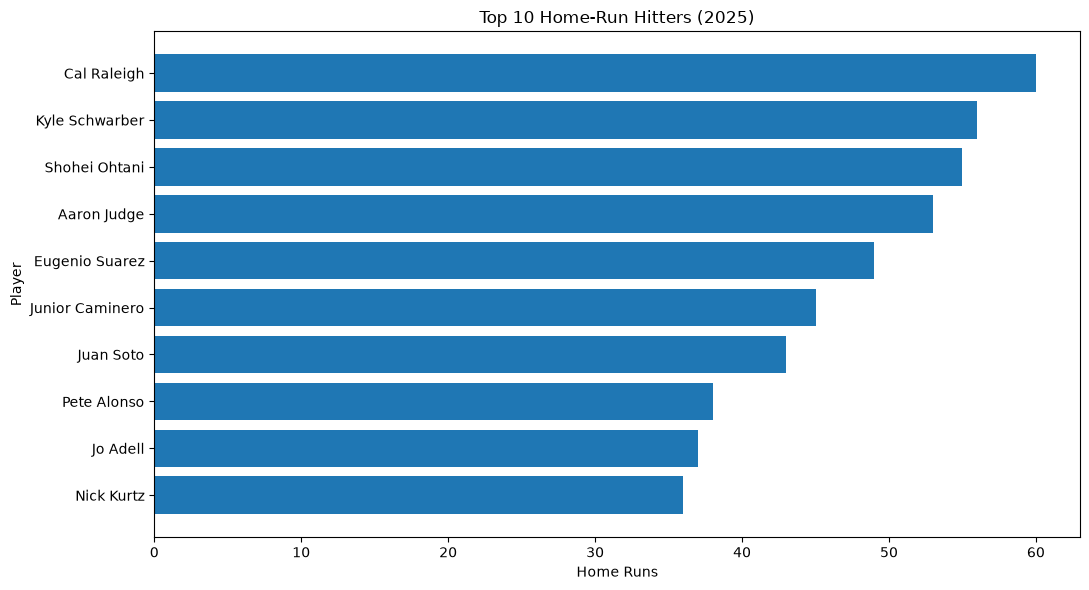

In [142]:
plt.figure(figsize=(11, 6))

plt.barh(
    top_hr["player_name"],
    top_hr["HR"]
)

plt.gca().invert_yaxis()

plt.title(f"Top 10 Home-Run Hitters ({selected_year})")
plt.xlabel("Home Runs")
plt.ylabel("Player")

plt.tight_layout()
plt.savefig("outputs/top_10_home_run_hitters.png", dpi=300)
plt.show()

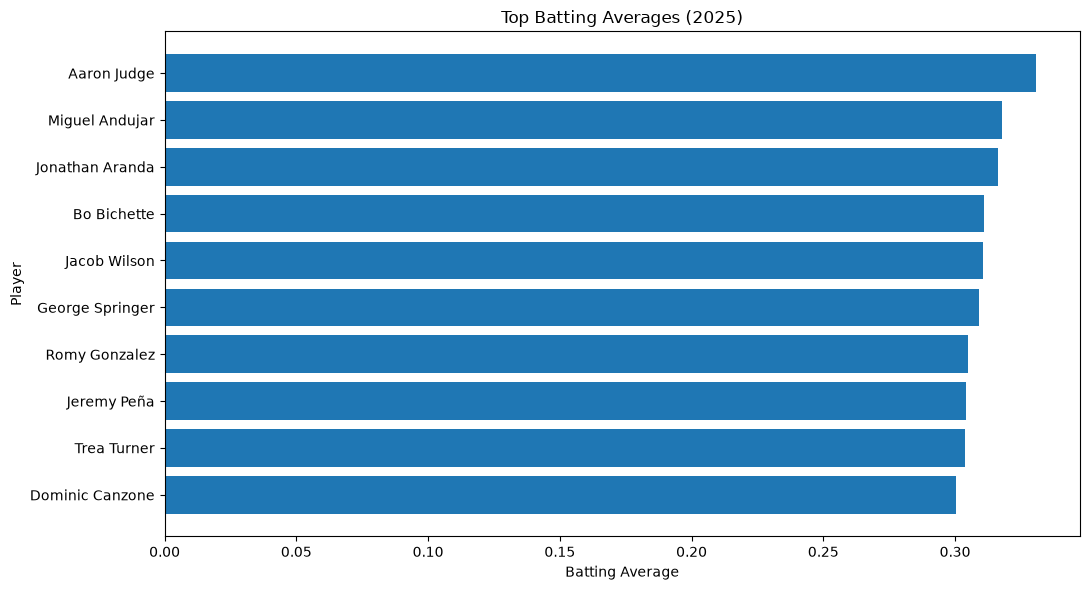

Correlation between HR and RBI: 0.841


In [143]:
top_avg = (
    eligible[eligible["AB"] >= 200]
    .sort_values("AVG", ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_avg["player_name"],
    top_avg["AVG"]
)

plt.gca().invert_yaxis()

plt.title(f"Top Batting Averages ({selected_year})")
plt.xlabel("Batting Average")
plt.ylabel("Player")

plt.tight_layout()
plt.savefig("outputs/top_batting_averages.png", dpi=300)
plt.show()
correlation_data = stats[
    ["HR", "RBI"]
].dropna()

correlation = correlation_data["HR"].corr(
    correlation_data["RBI"]
)

print("Correlation between HR and RBI:", round(correlation, 3))

In [144]:
correlation_data = stats[
    ["HR", "RBI"]
].dropna()

correlation = correlation_data["HR"].corr(
    correlation_data["RBI"]
)

print("Correlation between HR and RBI:", round(correlation, 3))

Correlation between HR and RBI: 0.841


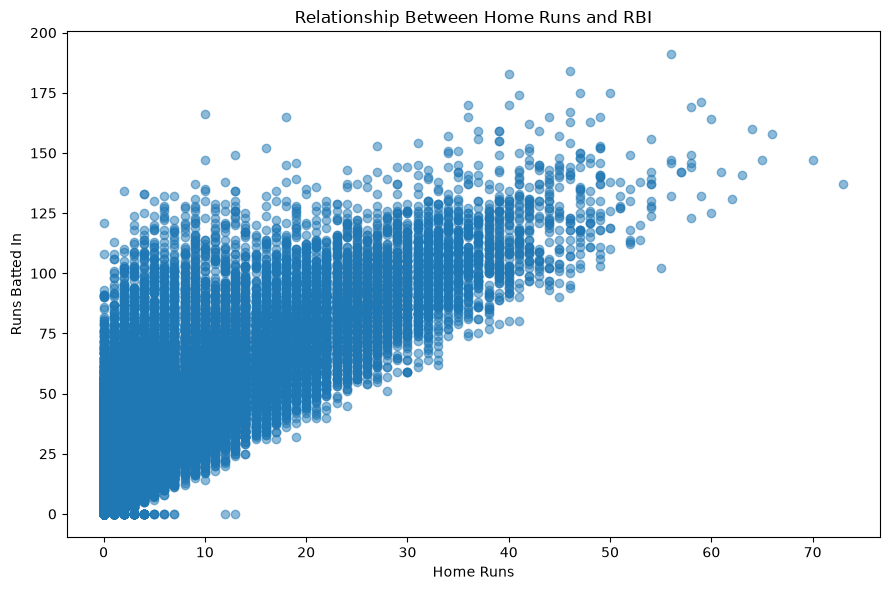

In [145]:
plt.figure(figsize=(9, 6))

plt.scatter(
    correlation_data["HR"],
    correlation_data["RBI"],
    alpha=0.5
)

plt.title("Relationship Between Home Runs and RBI")
plt.xlabel("Home Runs")
plt.ylabel("Runs Batted In")

plt.tight_layout()
plt.savefig("outputs/home_runs_vs_rbi.png", dpi=300)
plt.show()

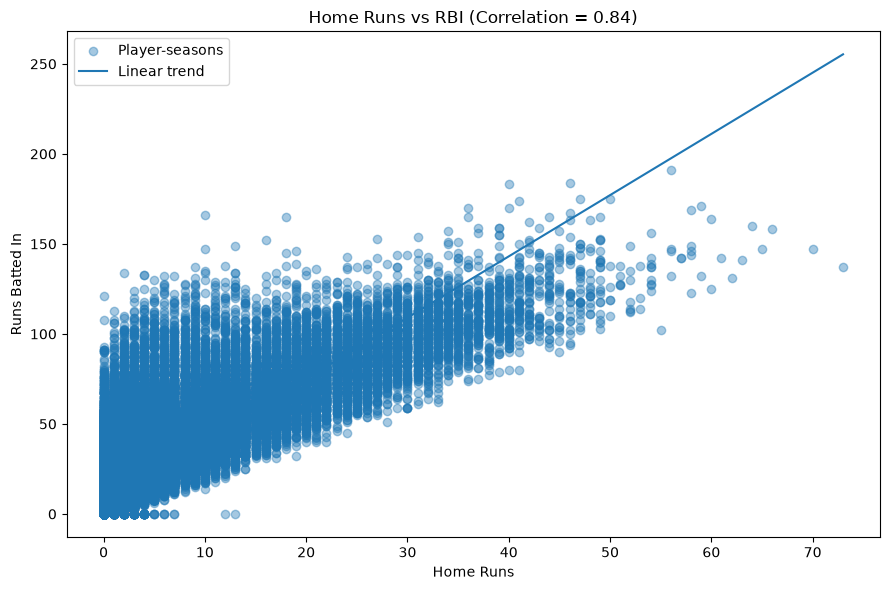

In [146]:
x = correlation_data["HR"]
y = correlation_data["RBI"]

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

plt.figure(figsize=(9, 6))

plt.scatter(x, y, alpha=0.4, label="Player-seasons")
plt.plot(
    x_line,
    y_line,
    label="Linear trend"
)

plt.title(
    f"Home Runs vs RBI (Correlation = {correlation:.2f})"
)
plt.xlabel("Home Runs")
plt.ylabel("Runs Batted In")
plt.legend()

plt.tight_layout()
plt.savefig("outputs/home_runs_vs_rbi_trend.png", dpi=300)
plt.show()

In [147]:
season_correlations = (
    stats.groupby("yearID")
    .apply(
        lambda group: group["HR"].corr(group["RBI"]),
        include_groups=False
    )
    .dropna()
)

print(season_correlations.tail(10))

yearID
2016    0.949845
2017    0.950765
2018    0.952493
2019    0.959383
2020    0.931953
2021    0.953185
2022    0.939496
2023    0.951556
2024    0.955546
2025    0.949077
dtype: float64


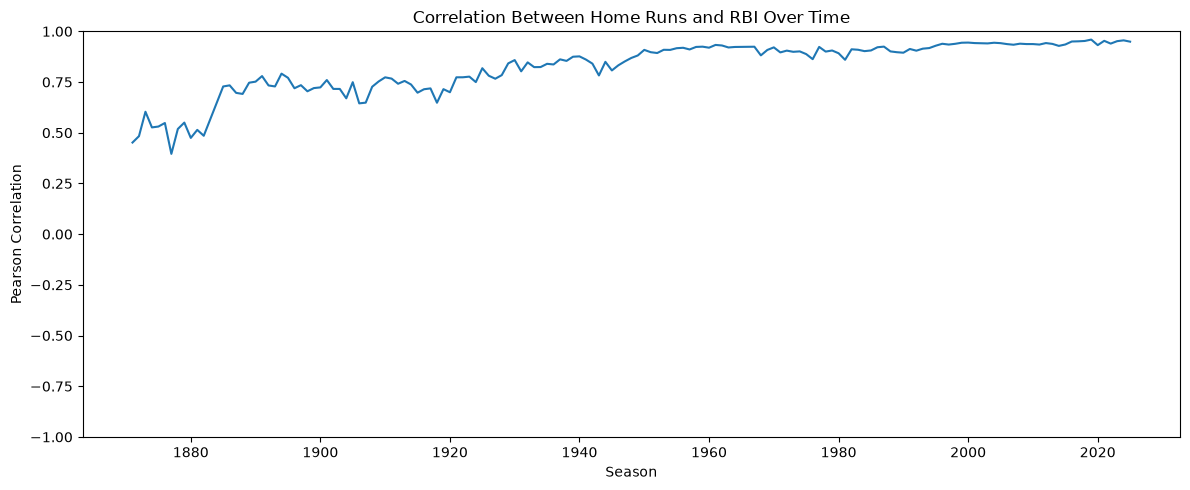

In [148]:
plt.figure(figsize=(12, 5))

plt.plot(
    season_correlations.index,
    season_correlations.values
)

plt.title("Correlation Between Home Runs and RBI Over Time")
plt.xlabel("Season")
plt.ylabel("Pearson Correlation")
plt.ylim(-1, 1)

plt.tight_layout()
plt.savefig("outputs/hr_rbi_correlation_over_time.png", dpi=300)
plt.show()

In [149]:
# Keep player-seasons with at least 100 at-bats
eligible_stats = stats[
    (stats["AB"] >= 100) &
    (stats["AB"] > 0)
].copy()

# Calculate each player's batting average
eligible_stats["AVG"] = (
    eligible_stats["H"] / eligible_stats["AB"]
)

# Calculate the average player batting average for each year
yearly_avg = (
    eligible_stats
    .groupby("yearID")["AVG"]
    .mean()
    .reset_index()
)

yearly_avg.columns = ["Year", "Average_Batting_Average"]

yearly_avg.head()

,Year,Average_Batting_Average
0,1871,0.293249
1,1872,0.293504
2,1873,0.291198
3,1874,0.274422
4,1875,0.250484


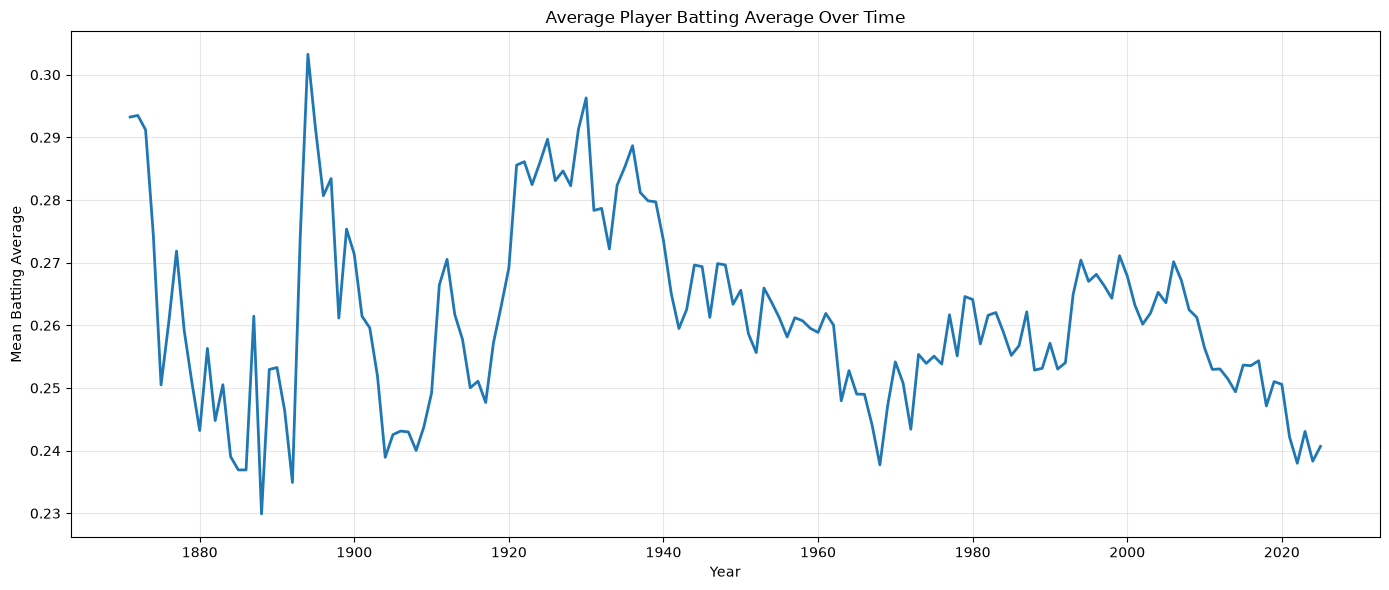

In [150]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_avg["Year"],
    yearly_avg["Average_Batting_Average"],
    linewidth=2
)

plt.title("Average Player Batting Average Over Time")
plt.xlabel("Year")
plt.ylabel("Mean Batting Average")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "outputs/average_batting_average_over_time.png",
    dpi=300
)
plt.show()

In [151]:
yearly_hr = (
    eligible_stats
    .groupby("yearID")
    .agg(
        Total_Home_Runs=("HR", "sum"),
        Average_Home_Runs=("HR", "mean"),
        Player_Seasons=("playerID", "count")
    )
    .reset_index()
)

yearly_hr.head()

,yearID,Total_Home_Runs,Average_Home_Runs,Player_Seasons
0,1871,39,0.619048,63
1,1872,36,0.571429,63
2,1873,47,0.661972,71
3,1874,39,0.520000,75
4,1875,40,0.421053,95


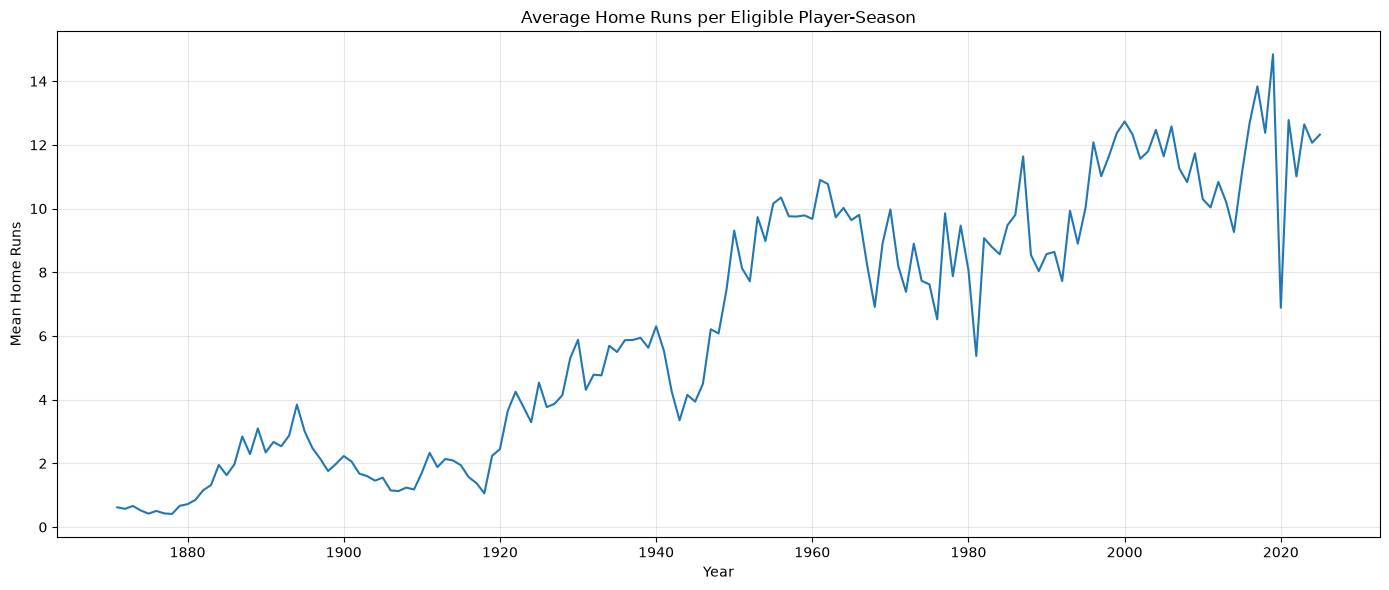

In [152]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_hr["yearID"],
    yearly_hr["Average_Home_Runs"]
)

plt.title("Average Home Runs per Eligible Player-Season")
plt.xlabel("Year")
plt.ylabel("Mean Home Runs")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "outputs/average_home_runs_over_time.png",
    dpi=300
)
plt.show()

In [153]:
selected_years = [1920, 1950, 1980, 2000, 2020]

comparison = yearly_avg[
    yearly_avg["Year"].isin(selected_years)
]

print(comparison.to_string(index=False))

 Year  Average_Batting_Average
 1920                 0.269185
 1950                 0.265593
 1980                 0.264129
 2000                 0.267879
 2020                 0.250578


In [154]:
selected_year = 2024

season_data = eligible_stats[
    eligible_stats["yearID"] == selected_year
].copy()

batting_averages = season_data["AVG"].dropna()

print("Number of players:", len(batting_averages))
print("Minimum AVG:", batting_averages.min())
print("Maximum AVG:", batting_averages.max())

Number of players: 439
Minimum AVG: 0.11851851851851852
Maximum AVG: 0.337037037037037


In [155]:
mean_avg = batting_averages.mean()
median_avg = batting_averages.median()
std_avg = batting_averages.std()
skewness = batting_averages.skew()

print("Mean:", round(mean_avg, 4))
print("Median:", round(median_avg, 4))
print("Standard deviation:", round(std_avg, 4))
print("Skewness:", round(skewness, 4))

Mean: 0.2383
Median: 0.2381
Standard deviation: 0.0337
Skewness: -0.2226


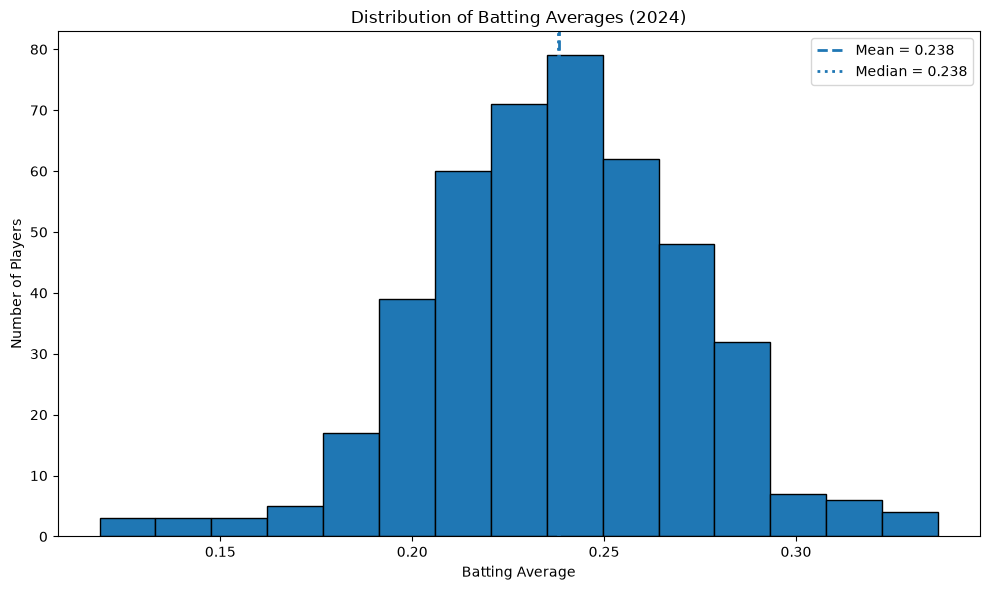

In [156]:
plt.figure(figsize=(10, 6))

plt.hist(
    batting_averages,
    bins=15,
    edgecolor="black"
)

plt.axvline(
    mean_avg,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_avg:.3f}"
)

plt.axvline(
    median_avg,
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_avg:.3f}"
)

plt.title(
    f"Distribution of Batting Averages ({selected_year})"
)
plt.xlabel("Batting Average")
plt.ylabel("Number of Players")
plt.legend()

plt.tight_layout()
plt.savefig(
    "outputs/batting_average_distribution.png",
    dpi=300
)
plt.show()

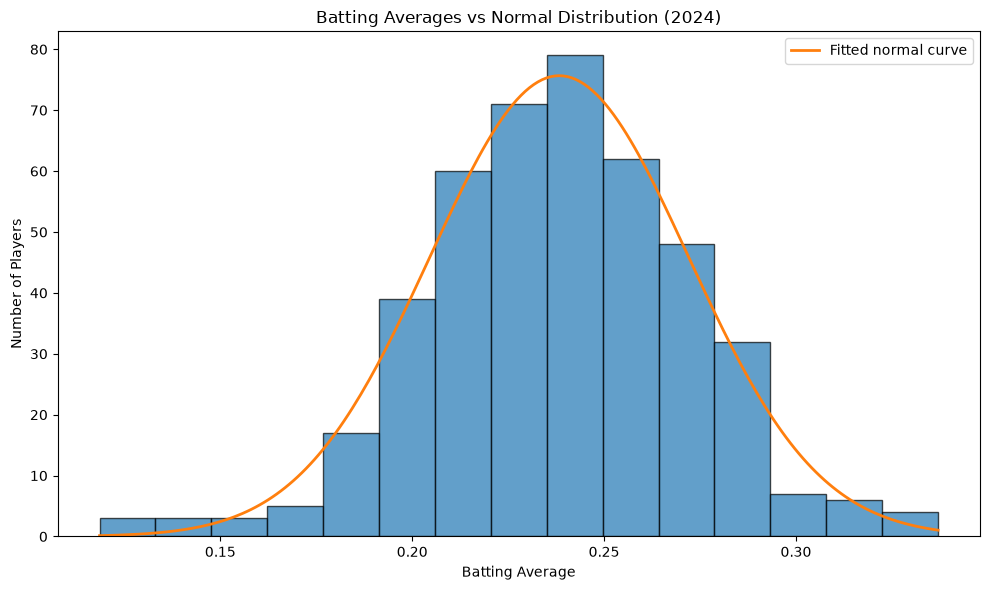

In [157]:
from scipy.stats import norm

x = np.linspace(
    batting_averages.min(),
    batting_averages.max(),
    200
)

# Scale the normal density to match histogram counts
bin_width = (
    batting_averages.max() - batting_averages.min()
) / 15

normal_curve = norm.pdf(
    x,
    loc=mean_avg,
    scale=std_avg
) * len(batting_averages) * bin_width

plt.figure(figsize=(10, 6))

plt.hist(
    batting_averages,
    bins=15,
    edgecolor="black",
    alpha=0.7
)

plt.plot(
    x,
    normal_curve,
    linewidth=2,
    label="Fitted normal curve"
)

plt.title(
    f"Batting Averages vs Normal Distribution ({selected_year})"
)
plt.xlabel("Batting Average")
plt.ylabel("Number of Players")
plt.legend()

plt.tight_layout()
plt.savefig(
    "outputs/batting_average_normal_curve.png",
    dpi=300
)
plt.show()

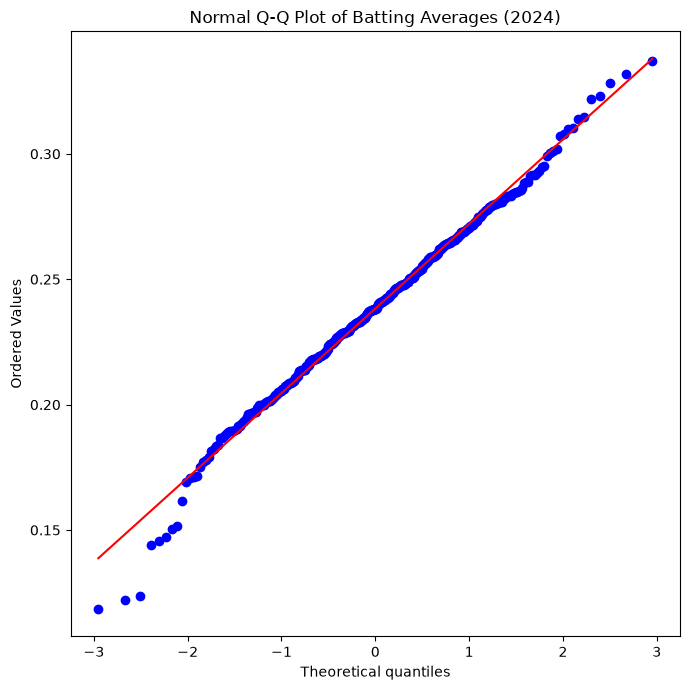

In [158]:
from scipy import stats as scipy_stats

plt.figure(figsize=(7, 7))

scipy_stats.probplot(
    batting_averages,
    dist="norm",
    plot=plt
)

plt.title(
    f"Normal Q-Q Plot of Batting Averages ({selected_year})"
)

plt.tight_layout()
plt.savefig(
    "outputs/batting_average_qq_plot.png",
    dpi=300
)
plt.show()

In [159]:
if len(batting_averages) >= 8:
    test_statistic, p_value = scipy_stats.normaltest(
        batting_averages
    )

    print("Test statistic:", round(test_statistic, 4))
    print("P-value:", p_value)

    alpha = 0.05

    if p_value < alpha:
        print(
            "Reject the null hypothesis: "
            "there is evidence that the data are not normally distributed."
        )
    else:
        print(
            "Fail to reject the null hypothesis: "
            "there is insufficient evidence to conclude that the "
            "data depart from normality."
        )
else:
    print("There are too few observations for this test.")

Test statistic: 9.8424
P-value: 0.007290557366560178
Reject the null hypothesis: there is evidence that the data are not normally distributed.
